In [ ]:
import os
import re
import rasterio
import numpy as np
import matplotlib.pyplot as plt


  

In [2]:
data_path="../dataset/sentinel_high/"

In [3]:
# Rename file, run once
# for f in os.listdir(data_path):
#     match = re.search(r".*_(B\d{2})_\(Raw\)\.tiff", f)
#     if match:
#         new_name = f"{match.group(1)}.tiff"
#         old_path = os.path.join(data_path, f)
#         new_path = os.path.join(data_path, new_name)

#         os.rename(old_path, new_path)
#         print(f"Berhasil mengubah: {f} -> {new_name}")

In [4]:
data = []
for f in os.listdir(data_path):
    file_path = os.path.join(data_path, f)
    with rasterio.open(file_path) as src:
        data.append(src.read(1))

In [5]:
ndvi = np.zeros(data[0].shape, float) # ( B8 - B4 ) / ( B8 + B4 )

for i in range(0, data[0].shape[0]):
    for j in range(0, data[0].shape[1]):
        b8 = float(data[7][i][j])
        b4 = float(data[3][i][j])

        if b8 + b4 == 0:
            ndvi[i][j] = 0
        else:
            ndvi[i][j] = (b8 - b4) / (b8 + b4)

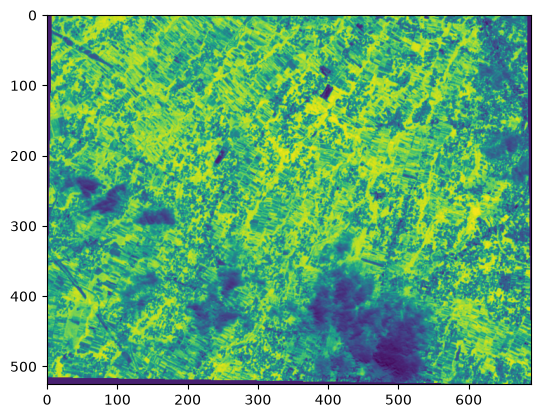

In [7]:
plt.imshow(ndvi)